# Automated Digital Forensic Investigation

This notebook connects behavioral risk detection with raw event evidence.

The investigation workflow is:

**Risky User-Day → Raw Events → Event Timeline → Evidence Summary → Investigation Priority**

Event types include:
- LOGON
- USB
- HTTP

URLs from the CERT dataset are synthetic/generated artifacts and must not be visited.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = os.path.abspath("..")
PROCESSED_DIR = os.path.join(BASE_DIR, "dataset", "processed")

timeline_path = os.path.join(
    PROCESSED_DIR,
    "Forensic_Timeline.csv"
)

evidence_path = os.path.join(
    PROCESSED_DIR,
    "Threat_Evidence_Correlated.csv"
)

timeline = pd.read_csv(timeline_path)
evidence = pd.read_csv(evidence_path)

timeline["day"] = pd.to_datetime(timeline["day"])
evidence["day"] = pd.to_datetime(evidence["day"])

print("Forensic events:", len(timeline))
print("Investigation cases:", len(evidence))

Forensic events: 2990365
Investigation cases: 89826


In [2]:
print("Forensic event types:")
display(
    timeline["event_type"]
    .value_counts()
    .to_frame("events")
)

Forensic event types:


,events
event_type,
HTTP,2614932
LOGON,309765
USB,65668


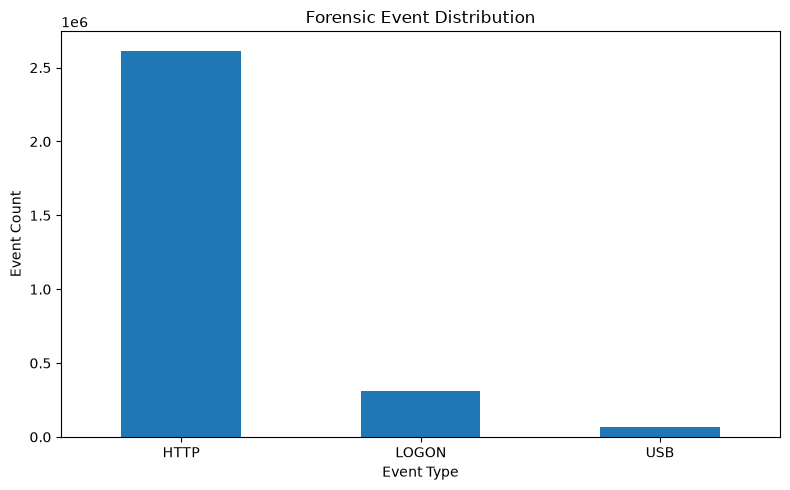

In [3]:
plt.figure(figsize=(8, 5))

timeline["event_type"].value_counts().plot(kind="bar")

plt.title("Forensic Event Distribution")
plt.xlabel("Event Type")
plt.ylabel("Event Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
print("Investigation priority distribution:")

display(
    explanations["investigation_priority"]
    .value_counts()
    .to_frame("cases")
)

Investigation priority distribution:


,cases
investigation_priority,
P4 - Monitor,135678
P3 - Review,109401
P2 - High Priority,59523
P1 - Immediate Investigation,30303


In [8]:
print(explanations.columns.tolist())

['user', 'user_id', 'day', 'Role', 'calibrated_risk_score', 'calibrated_risk_level', 'investigation_priority', 'login_count', 'after_hours_login', 'usb_connect_count', 'usb_disconnect_count', 'after_hours_usb', 'web_activity_count', 'unique_domains', 'after_hours_web', 'unique_pcs', 'work_duration_minutes', 'personal_anomaly_strength', 'role_anomaly_strength', 'behavioral_deviation_score', 'anomaly', 'investigation_required', 'explanation']


In [ ]:
evidence_columns = [
    "user_id",
    "day",
    "role",
    "calibrated_risk_score",
    "risk_level",
    "priority",
    "total_events",
    "logon_events",
    "usb_events",
    "http_events",
    "events_per_hour"
]

available_columns = [
    c for c in evidence_columns
    if c in evidence.columns
]

display(
    evidence[available_columns]
    .sort_values(
        "calibrated_risk_score",
        ascending=False
    )
    .head(25)
)

In [ ]:
top_case = (
    evidence
    .sort_values(
        "calibrated_risk_score",
        ascending=False
    )
    .iloc[0]
)

print("Top investigation case:")
print("User:", top_case["user_id"])
print("Date:", top_case["day"])
print("Role:", top_case["role"])
print("Risk:", top_case["calibrated_risk_score"])
print("Risk level:", top_case["risk_level"])
print("Priority:", top_case["priority"])
print("Total events:", top_case["total_events"])

In [ ]:
user_id = top_case["user_id"]
day = top_case["day"]

case_events = timeline[
    (timeline["user_id"] == user_id) &
    (timeline["day"] == day)
].copy()

case_events = case_events.sort_values("date")

print("Forensic timeline:")
display(
    case_events[
        [
            c for c in [
                "date",
                "event_type",
                "event_detail",
                "pc",
                "risk_level"
            ]
            if c in case_events.columns
        ]
    ].head(100)
)

In [ ]:
print("Evidence summary:")
print(top_case.get("forensic_summary", "Evidence summary unavailable"))

## Interpretation

A high-risk user-day should be interpreted as an **investigation priority**, not as proof of malicious activity.

The forensic timeline allows an analyst to move from a statistical anomaly to the underlying activity sequence and investigate the case in context.